# BIVARIATE ANALYSIS #

In [1]:
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
from scipy.stats import chi2_contingency, pearsonr, spearmanr, kruskal

In [2]:
DATA_DIR = Path('data')

In [3]:
df = pd.read_csv(DATA_DIR/"ChainStore.csv", sep=';')
df.head()

,Category,City,Country/Region,Customer Name,Manufacturer,Order Date,Order ID,Postal Code,Product Name,Region,...,Ship Date,Ship Mode,State,Sub-Category,Discount,Number of Records,Profit,Profit Ratio,Quantity,Sales
0,Furniture,Henderson,United States,Claire Gute,Bush,08/11/2018,CA-2018-152156,42420.0,Bush Somerset Collection Bookcase,South,...,11/11/2018,Second Class,Kentucky,Bookcases,0%,1,$42,16%,2,$262
1,Furniture,Henderson,United States,Claire Gute,Hon,08/11/2018,CA-2018-152156,42420.0,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",South,...,11/11/2018,Second Class,Kentucky,Chairs,0%,1,$220,30%,3,$732
2,Office Supplies,Los Angeles,United States,Darrin Van Huff,Universal,12/06/2018,CA-2018-138688,90036.0,Self-Adhesive Address Labels for Typewriters b...,West,...,16/06/2018,Second Class,California,Labels,0%,1,$7,47%,2,$15
3,Furniture,Fort Lauderdale,United States,Sean O'Donnell,Bretford,11/10/2017,US-2017-108966,33311.0,Bretford CR4500 Series Slim Rectangular Table,South,...,18/10/2017,Standard Class,Florida,Tables,45%,1,-$383,-40%,5,$958
4,Office Supplies,Fort Lauderdale,United States,Sean O'Donnell,Eldon,11/10/2017,US-2017-108966,33311.0,Eldon Fold 'N Roll Cart System,South,...,18/10/2017,Standard Class,Florida,Storage,20%,1,$3,11%,2,$22


## Cleaning the data ##

In [4]:
def clean_money(series):
    cleaned = series.str.replace('$', "", regex=False)
    cleaned = cleaned.str.replace("\xa0", "", regex=False)
    return pd.to_numeric(cleaned)

def clean_percent(series):
    cleaned = series.str.replace('%', "", regex=False)
    cleaned = pd.to_numeric(cleaned)
    return (cleaned / 100)

df["Sales"] = clean_money(df["Sales"])
df["Profit"] = clean_money(df["Profit"])
df["Discount"] = clean_percent(df["Discount"])
df["Profit Ratio"] = clean_percent(df["Profit Ratio"])

df["Order Date"] = pd.to_datetime(df["Order Date"], format='%d/%m/%Y')
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format='%d/%m/%Y')

We divide by 100 in `clean_percent` to obtain a ratio (from 0 to 1), which is more understandable from a discount point of view.

In [5]:
df.dtypes

Category                     object
City                         object
Country/Region               object
Customer Name                object
Manufacturer                 object
Order Date           datetime64[ns]
Order ID                     object
Postal Code                 float64
Product Name                 object
Region                       object
Segment                      object
Ship Date            datetime64[ns]
Ship Mode                    object
State                        object
Sub-Category                 object
Discount                    float64
Number of Records             int64
Profit                        int64
Profit Ratio                float64
Quantity                      int64
Sales                         int64
dtype: object

In [6]:
df[["Sales", "Profit", "Discount", "Profit Ratio", "Order Date", "Ship Date"]].isna().sum()

Sales           0
Profit          0
Discount        0
Profit Ratio    0
Order Date      0
Ship Date       0
dtype: int64

In [7]:
df[["Discount"]].describe()

,Discount
count,9994.000000
mean,0.156203
std,0.206452
min,0.000000
25%,0.000000
50%,0.200000
75%,0.200000
max,0.800000


Pair 1 : Profit Ratio vs Discount (num - num association) <br>
Question : Is the discount level associated with profitability?


In [8]:
display(df[["Profit Ratio", "Discount"]].corr(method="pearson"))
display(df[["Profit Ratio", "Discount"]].corr(method="spearman"))
df.groupby("Discount")["Profit Ratio"].agg(["mean", "median", "count"])

,Profit Ratio,Discount
Profit Ratio,1.000000,-0.864166
Discount,-0.864166,1.000000


,Profit Ratio,Discount
Profit Ratio,1.000000,-0.644574
Discount,-0.644574,1.000000


,mean,median,count
Discount,,,
0.00,0.340160,0.34,4798
0.10,0.156064,0.17,94
0.15,0.034038,0.05,52
0.20,0.177495,0.18,3657
0.30,-0.114934,-0.09,227
0.32,-0.174815,-0.18,27
0.40,-0.222670,-0.23,206
0.45,-0.455455,-0.44,11
0.50,-0.549091,-0.60,66


In [9]:
# Significance of the correlations
r, p_r = pearsonr(df["Discount"], df["Profit Ratio"])
rho, p_rho = spearmanr(df["Discount"], df["Profit Ratio"])

print(f"Pearson r = {r:.3f}, p-value = {p_r:.2e}")
print(f"Spearman rho = {rho:.3f}, p-value = {p_rho:.2e}")

Pearson r = -0.864, p-value = 0.00e+00
Spearman rho = -0.645, p-value = 0.00e+00


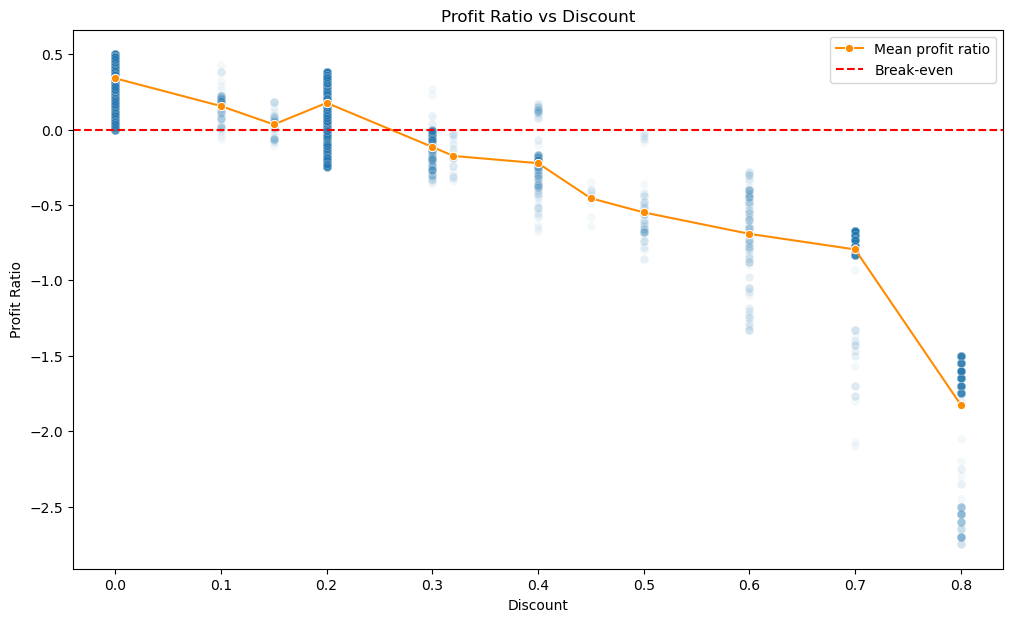

In [10]:
# Visualization
plt.figure(figsize=(12, 7))
sb.scatterplot(data=df, x="Discount", y="Profit Ratio", alpha=0.05)
sb.lineplot(data=df, x="Discount", y="Profit Ratio", estimator="mean",
            errorbar=None, color="darkorange", marker="o", label="Mean profit ratio")
plt.axhline(0, linestyle="--", color="red", label="Break-even")
plt.title("Profit Ratio vs Discount")
plt.xlabel("Discount")
plt.ylabel("Profit Ratio")
plt.legend()
plt.show()

Pair 2 : Region vs Profit (cat-num association) <br>
Question : Does the profit differ across regions, and are some regions associated with losses? <br>

In [11]:
df.groupby("Region")["Profit"].agg(["mean", "median", "count", "sum"]).sort_values(by="sum", ascending=False)

,mean,median,count,sum
Region,,,,
West,33.838901,11.0,3203,108386
East,32.135183,8.0,2848,91521
South,28.840123,9.0,1620,46721
Central,17.098149,5.0,2323,39719


In [12]:
loss_share = df.groupby("Region")["Profit"].apply(lambda s: (s < 0).mean()).sort_values(ascending=False)
loss_share

Region
Central    0.317693
East       0.193820
South      0.159877
West       0.098658
Name: Profit, dtype: float64

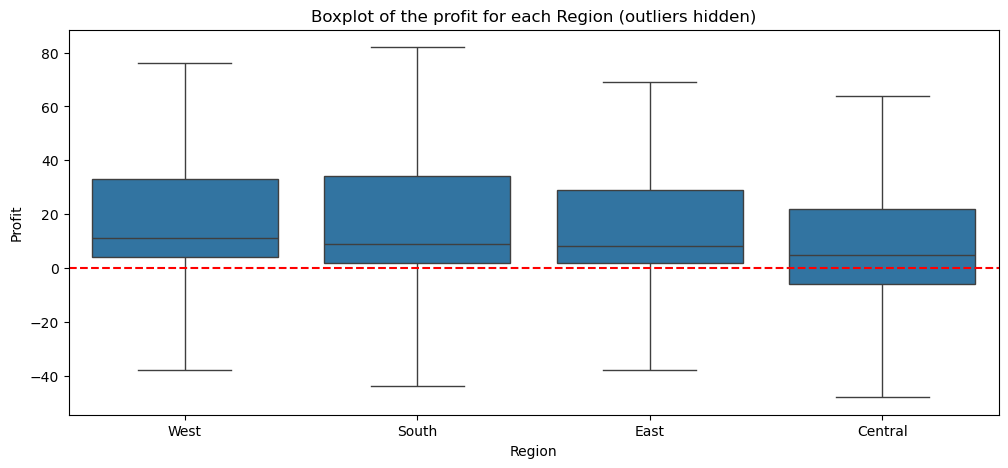

In [14]:
order = df.groupby("Region")["Profit"].median().sort_values(ascending=False).index

plt.figure(figsize=(12, 5))
sb.boxplot(data=df, x="Region", y="Profit", order=order, showfliers=False)
plt.axhline(0, linestyle="--", color="red")
plt.title("Boxplot of the profit for each Region (outliers hidden)"); plt.xlabel("Region"); plt.ylabel("Profit")
plt.show()


Pair 3 : Segment vs Category (cat - cat association) <br>
Question : Does the product category mix differ between Consumer, Corporate and Home Office customers?

In [15]:
pd.crosstab(df["Segment"], df["Category"], margins=True)

Category,Furniture,Office Supplies,Technology,All
Segment,,,,
Consumer,1113,3127,951,5191
Corporate,646,1820,554,3020
Home Office,362,1079,342,1783
All,2121,6026,1847,9994


In [16]:
row_pct = pd.crosstab(df["Segment"], df["Category"], normalize="index") * 100
row_pct.round(1)

Category,Furniture,Office Supplies,Technology
Segment,,,
Consumer,21.4,60.2,18.3
Corporate,21.4,60.3,18.3
Home Office,20.3,60.5,19.2


In [17]:
counts = pd.crosstab(df["Segment"], df["Category"])
chi2, p, dof, expected = chi2_contingency(counts)

n = counts.sum().sum()
k = min(counts.shape) - 1
cramers_v = (chi2 / (n * k)) ** 0.5

print(f"chi2 = {chi2:.2f}, p-value = {p:.4f}, dof = {dof}, Cramér's V = {cramers_v:.3f}")

chi2 = 1.46, p-value = 0.8335, dof = 4, Cramér's V = 0.009


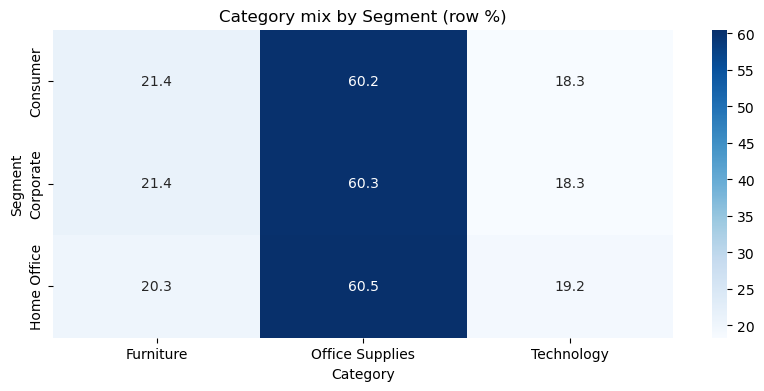

In [18]:
plt.figure(figsize=(10, 4))
sb.heatmap(row_pct, annot=True, fmt="0.1f", cmap="Blues")
plt.title("Category mix by Segment (row %)"); plt.xlabel("Category"); plt.ylabel("Segment")
plt.show()

Pair 4 : Ship Mode vs Shipping Days (cat - num association) <br>
Question : Do faster (and more expensive) ship modes actually correspond to shorter delays between order and shipment?

In [19]:
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Shipping Days"].describe()

count    9994.000000
mean        3.958075
std         1.747937
min         0.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         7.000000
Name: Shipping Days, dtype: float64

In [20]:
df.groupby("Ship Mode")["Shipping Days"].agg(["mean", "median", "count", "min", "max"]).sort_values(by="mean")

,mean,median,count,min,max
Ship Mode,,,,,
Same Day,0.044199,0.0,543,0,1
First Class,2.182705,2.0,1538,1,5
Second Class,3.237532,3.0,1945,1,5
Standard Class,5.006535,5.0,5968,3,7


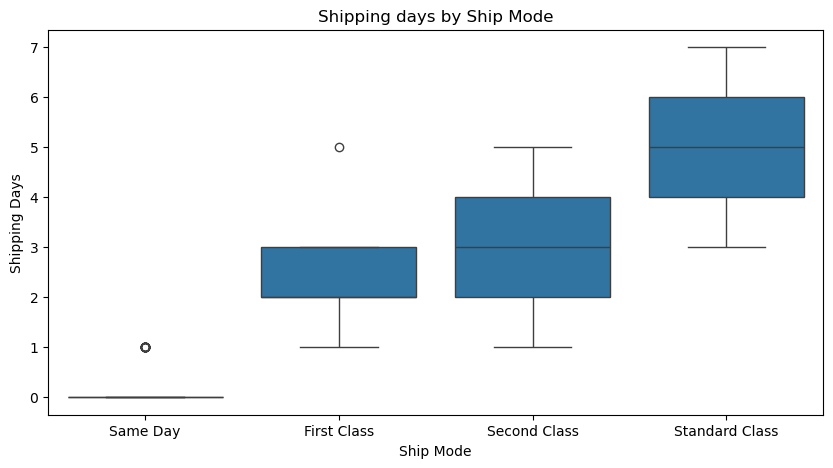

In [22]:
mode_order = ["Same Day", "First Class", "Second Class", "Standard Class"]
plt.figure(figsize=(10, 5))
sb.boxplot(data=df, x="Ship Mode", y="Shipping Days", order=mode_order)
plt.title("Shipping days by Ship Mode"); plt.xlabel("Ship Mode"); plt.ylabel("Shipping Days")
plt.show()

Pair 5 : Sub-Category vs Profit (cat - num association) <br>
Question : Which sub-categories generate the most profit, and which are associated with losses?

In [23]:
sub_stats = df.groupby("Sub-Category")["Profit"].agg(["mean", "median", "count", "sum"]).sort_values(by="sum", ascending=False)   
sub_stats

,mean,median,count,sum
Sub-Category,,,,
Copiers,817.911765,333.0,68,55618
Phones,50.047244,24.0,889,44492
Accessories,54.105806,21.0,775,41932
Paper,24.856204,12.0,1370,34053
Binders,19.829284,4.0,1523,30200
Chairs,43.089141,13.0,617,26586
Storage,25.153664,8.0,846,21280
Appliances,38.909871,17.5,466,18132
Furnishings,13.657262,9.0,957,13070


In [24]:
sub_loss = df.groupby("Sub-Category")["Profit"].apply(lambda s: (s < 0).mean()).sort_values(ascending=False)
sub_loss

Sub-Category
Tables         0.636364
Bookcases      0.478070
Binders        0.402495
Machines       0.382609
Chairs         0.380875
Storage        0.189125
Furnishings    0.173459
Supplies       0.168421
Phones         0.152981
Appliances     0.143777
Accessories    0.113548
Fasteners      0.055300
Labels         0.000000
Paper          0.000000
Envelopes      0.000000
Copiers        0.000000
Art            0.000000
Name: Profit, dtype: float64

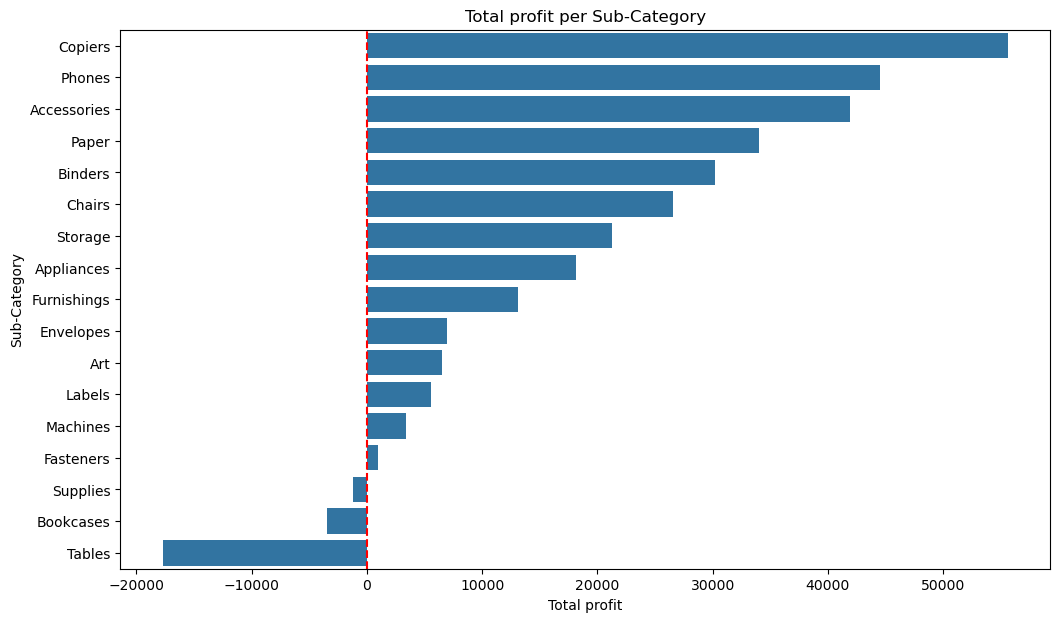

In [26]:
plt.figure(figsize=(12, 7))
sb.barplot(x=sub_stats["sum"], y=sub_stats.index, orient="h")
plt.axvline(0, color="red", linestyle="--")
plt.title("Total profit per Sub-Category"); plt.xlabel("Total profit"); plt.ylabel("Sub-Category")
plt.show()